In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
def f(x):
    return 3*x**2 - 4*x + 5

In [6]:
f(3.0)

20.0

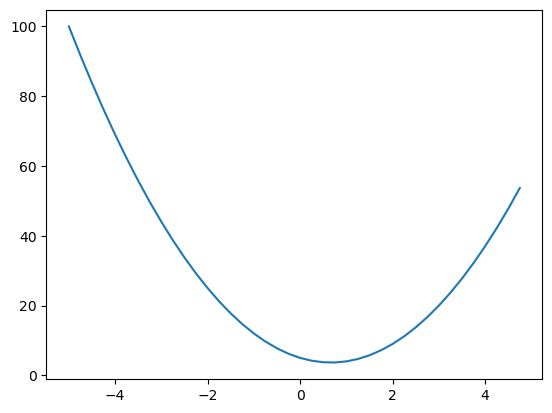

In [8]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs,ys)

In [22]:
# 搞点复杂的
a = 2.0
b = -3.0
c = 10.0
d = a*b+c
print(d)

4.0


In [26]:
h = 0.0001

#输入
a = 2.0
b = -3.0
c = 10.0

d1 = a*b+c
b += h
d2 = a*b+c

print('d1',d1)
print('d2',d2)
print('slot',(d2-d1)/(h))


d1 4.0
d2 4.0002
slot 2.0000000000042206


In [84]:
import math

class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data=data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0.0
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out

    def __neg__(self):
        return self * -1
    
    def __sub__(self, other):
        return self + (-other)    
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self, ), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward

        return out
    
    def __rmul__(self, other):# other * self
        return self * other

    def __truediv__(self, other):# self / other
        return self * other**-1
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1-t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad  
        out._backward = _backward
        return out
    
    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [14]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ data %.4f | grad %.4f }" % (n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

In [18]:
a = Value(2, label='a')
b = Value(-3, label='b')
c = Value(10, label='c')
e = a*b; e.label = 'e'
d = e+c; d.label = 'd'
f=Value(-2); f.label='f'
L=d*f;L.label='L'
L

Value(data=-8)

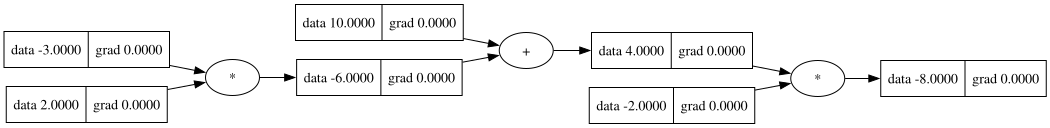

In [19]:
draw_dot(L)

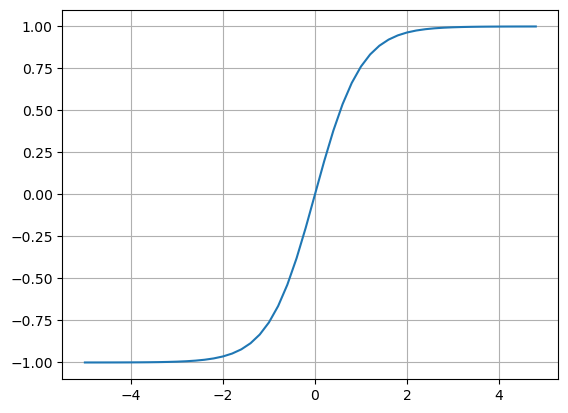

In [20]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2)));plt.grid() 

In [78]:
#输入
x1 = Value(2.0)
x2 = Value(0.0)
#权重
w1 = Value(-3.0)
w2 = Value(1.0)
#偏置
b = Value(6.8813735870195432)
# x1w1 + x2w2 + b
x1w1 = x1*w1
x2w2 = x2*w2
x1w1x2w2 = x1w1 + x2w2
n = x1w1x2w2 + b
o = n.tanh()
o.backward()

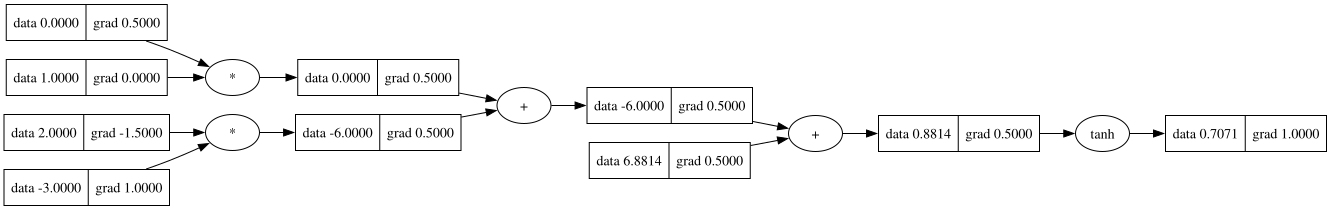

In [79]:
draw_dot(o)

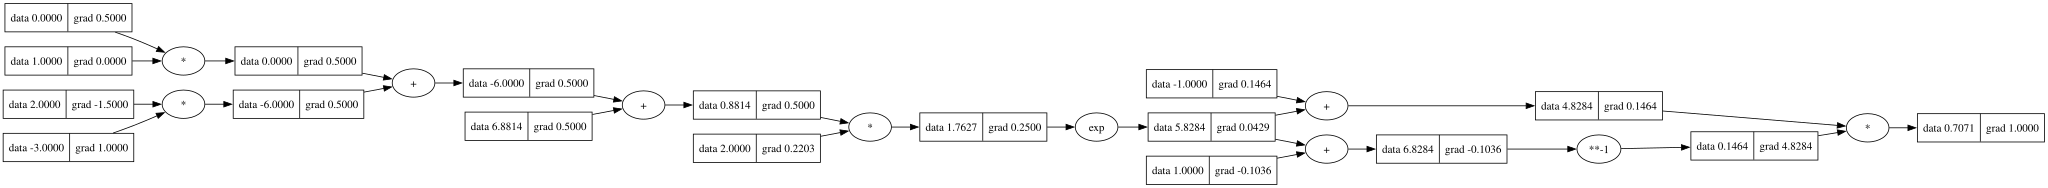

In [85]:
#输入
x1 = Value(2.0)
x2 = Value(0.0)
#权重
w1 = Value(-3.0)
w2 = Value(1.0)
#偏置
b = Value(6.8813735870195432)
# x1w1 + x2w2 + b
x1w1 = x1*w1
x2w2 = x2*w2
x1w1x2w2 = x1w1 + x2w2
n = x1w1x2w2 + b
#-----------
e = (2*n).exp()
o = (e - 1) / (e + 1)
#-----------
o.backward()
draw_dot(o)

In [1]:
import torch

In [4]:
x1 = torch.Tensor([2.0]).double()                      ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                      ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()                     ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                      ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()        ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("------------")
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
------------
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737
